## Decision Tree Classification — Phishing Dataset

In [3]:
lazy import numpy as np
lazy import pandas as pd
lazy import matplotlib.pyplot as plt
lazy import seaborn as sns
lazy import joblib

lazy from scipy.io import arff
lazy from sklearn.model_selection import train_test_split, GridSearchCV
lazy from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
lazy from sklearn.tree import DecisionTreeClassifier, plot_tree
lazy from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
lazy from sklearn.pipeline import Pipeline

### 1. Load the phishing dataset from an ARFF file

Place the `.arff` dataset file in the same folder as this notebook. If its name differs, update `file_path` below.

In [4]:
file_path = "Training Dataset.arff"  

raw_data, metadata = arff.loadarff(file_path)
df = pd.DataFrame(raw_data)

                                                                                         
for column in df.select_dtypes(include=["object"]).columns:
    df[column] = df[column].map(
        lambda value: value.decode("utf-8") if isinstance(value, bytes) else value
    )

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
display(df.head())

Number of rows: 11055
Number of columns: 31


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


### 2. Check for missing or null values

In [5]:
print("Missing values in each column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

print("Total missing values:", df.isnull().sum().sum())

Missing values in each column:


,Missing Values
having_IP_Address,0
URL_Length,0
Shortining_Service,0
having_At_Symbol,0
double_slash_redirecting,0
Prefix_Suffix,0
having_Sub_Domain,0
SSLfinal_State,0
Domain_registeration_length,0
Favicon,0


Total missing values: 0


If missing values existed, numerical features could be imputed with the median and categorical features with the most frequent value. If only a small number of rows had missing target labels, those rows should usually be removed because the correct class is unknown. This dataset should be checked before deciding on a treatment; do not assume missing values exist.

### 3. Identify features and target

This cell tries common target-column names. If the target is named differently in your ARFF file, set `target_column` manually after inspecting `df.columns`.

In [6]:
print("Columns:", df.columns.tolist())

possible_targets = ["Result", "result", "class", "Class", "target", "Target", "label", "Label"]
target_column = next((col for col in possible_targets if col in df.columns), None)

if target_column is None:
    raise ValueError(
        "Could not identify the target column automatically. "
        "Set target_column to the class/label column shown in df.columns."
    )

X = df.drop(columns=[target_column]).copy()
y = df[target_column].copy()

                                                                                         
print("Target column:", target_column)
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:")
display(y.value_counts(dropna=False).to_frame(name="Count"))

Columns: ['having_IP_Address', 'URL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report', 'Result']
Target column: Result
Feature shape: (11055, 30)
Target shape: (11055,)
Target classes:


,Count
Result,
1,6157
-1,4898


### 4. Compare feature scaling techniques

Decision Trees split features using threshold comparisons, so scaling usually does not improve their performance. The following cell compares StandardScaler, MinMaxScaler, and RobustScaler on the feature data and checks Decision Tree accuracy using the same train/test split. The best scaler is therefore judged by test accuracy, while noting that no scaling is normally necessary for a Decision Tree.

In [7]:
                                                                                 
X_encoded = pd.get_dummies(X, drop_first=False)

                                                                                  
X_encoded = X_encoded.replace([np.inf, -np.inf], np.nan)
X_encoded = X_encoded.fillna(X_encoded.median(numeric_only=True))
X_encoded = X_encoded.fillna(0)

                                                                         
valid_target = y.notna()
X_encoded = X_encoded.loc[valid_target].copy()
y = y.loc[valid_target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.25, random_state=42, stratify=y
)

scalers = {
    "No Scaling": None,
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler()
}

scaling_results = []

for scaler_name, scaler in scalers.items():
    if scaler is None:
        X_train_scaled = X_train
        X_test_scaled = X_test
    else:
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

    scaler_model = DecisionTreeClassifier(criterion="gini", random_state=42)
    scaler_model.fit(X_train_scaled, y_train)
    scaler_pred = scaler_model.predict(X_test_scaled)

    scaling_results.append({
        "Technique": scaler_name,
        "Accuracy": accuracy_score(y_test, scaler_pred)
    })

scaling_results_df = pd.DataFrame(scaling_results).sort_values(
    "Accuracy", ascending=False
)
display(scaling_results_df)

,Technique,Accuracy
0,No Scaling,0.963459
1,StandardScaler,0.963459
2,MinMaxScaler,0.963459
3,RobustScaler,0.963459


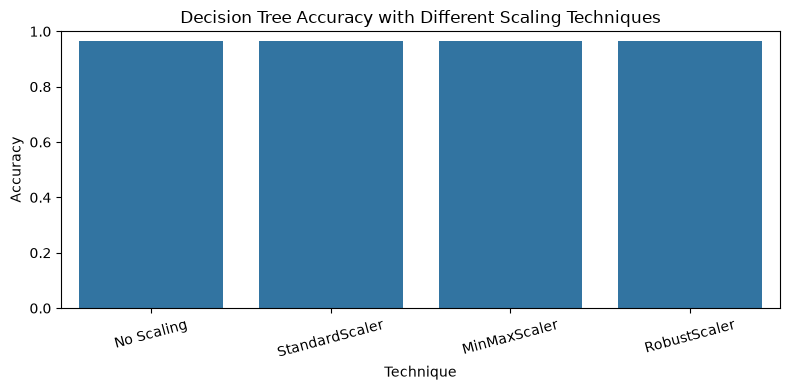

In [8]:
plt.figure(figsize=(8, 4))
sns.barplot(data=scaling_results_df, x="Technique", y="Accuracy")
plt.title("Decision Tree Accuracy with Different Scaling Techniques")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

For a Decision Tree, scaling is generally unnecessary because the order of feature values and threshold-based splits are preserved by these monotonic transformations. If the accuracies are equal or nearly equal, that is expected; choose no scaling for the final tree unless your measured results show a meaningful and reproducible difference.

### 5. Split the dataset into training and testing sets (75:25)

In [9]:
print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target size:", y_train.shape[0])
print("Testing target size:", y_test.shape[0])

Training feature shape: (8291, 68)
Testing feature shape: (2764, 68)
Training target size: 8291
Testing target size: 2764


### 6. Train a Decision Tree Classifier using Gini criterion

In [10]:
dt_gini = DecisionTreeClassifier(criterion="gini", random_state=42)
dt_gini.fit(X_train, y_train)
print("Gini Decision Tree trained successfully.")

Gini Decision Tree trained successfully.


### 7. Predict labels for the test set

In [11]:
y_pred_gini = dt_gini.predict(X_test)
print("First 20 predictions:", y_pred_gini[:20])

First 20 predictions: ['-1' '1' '-1' '-1' '-1' '1' '1' '1' '1' '1' '1' '-1' '-1' '1' '-1' '1'
 '1' '1' '-1' '-1']


### 8. Confusion matrix and accuracy score

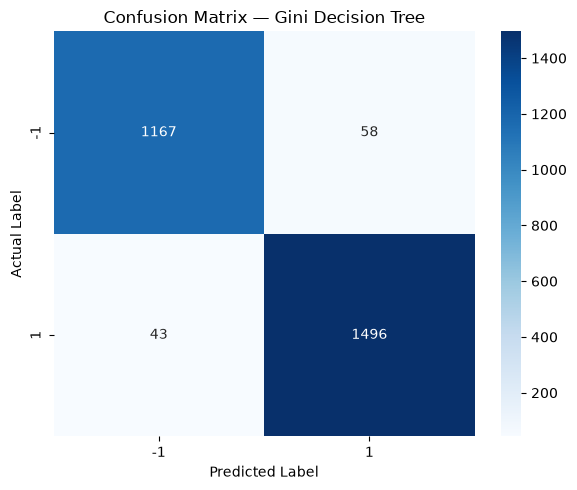

Accuracy: 0.9634587554269175

Classification report:
              precision    recall  f1-score   support

          -1       0.96      0.95      0.96      1225
           1       0.96      0.97      0.97      1539

    accuracy                           0.96      2764
   macro avg       0.96      0.96      0.96      2764
weighted avg       0.96      0.96      0.96      2764



In [12]:
cm_gini = confusion_matrix(y_test, y_pred_gini, labels=dt_gini.classes_)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_gini, annot=True, fmt="d", cmap="Blues",
    xticklabels=dt_gini.classes_, yticklabels=dt_gini.classes_
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix — Gini Decision Tree")
plt.tight_layout()
plt.show()

print("Accuracy:", accuracy_score(y_test, y_pred_gini))
print("\nClassification report:")
print(classification_report(y_test, y_pred_gini, zero_division=0))

### 9. Train using Entropy criterion and compare accuracy

In [13]:
dt_entropy = DecisionTreeClassifier(criterion="entropy", random_state=42)
dt_entropy.fit(X_train, y_train)
y_pred_entropy = dt_entropy.predict(X_test)

gini_accuracy = accuracy_score(y_test, y_pred_gini)
entropy_accuracy = accuracy_score(y_test, y_pred_entropy)

print("Gini accuracy:", gini_accuracy)
print("Entropy accuracy:", entropy_accuracy)
print("Accuracy difference (Entropy - Gini):", entropy_accuracy - gini_accuracy)

Gini accuracy: 0.9634587554269175
Entropy accuracy: 0.9688856729377714
Accuracy difference (Entropy - Gini): 0.00542691751085389


Gini and entropy are alternative criteria for measuring the quality of a split. Which performs better depends on the data; compare the measured test accuracies rather than assuming one is always superior.

### 10. Visualize the trained Decision Tree

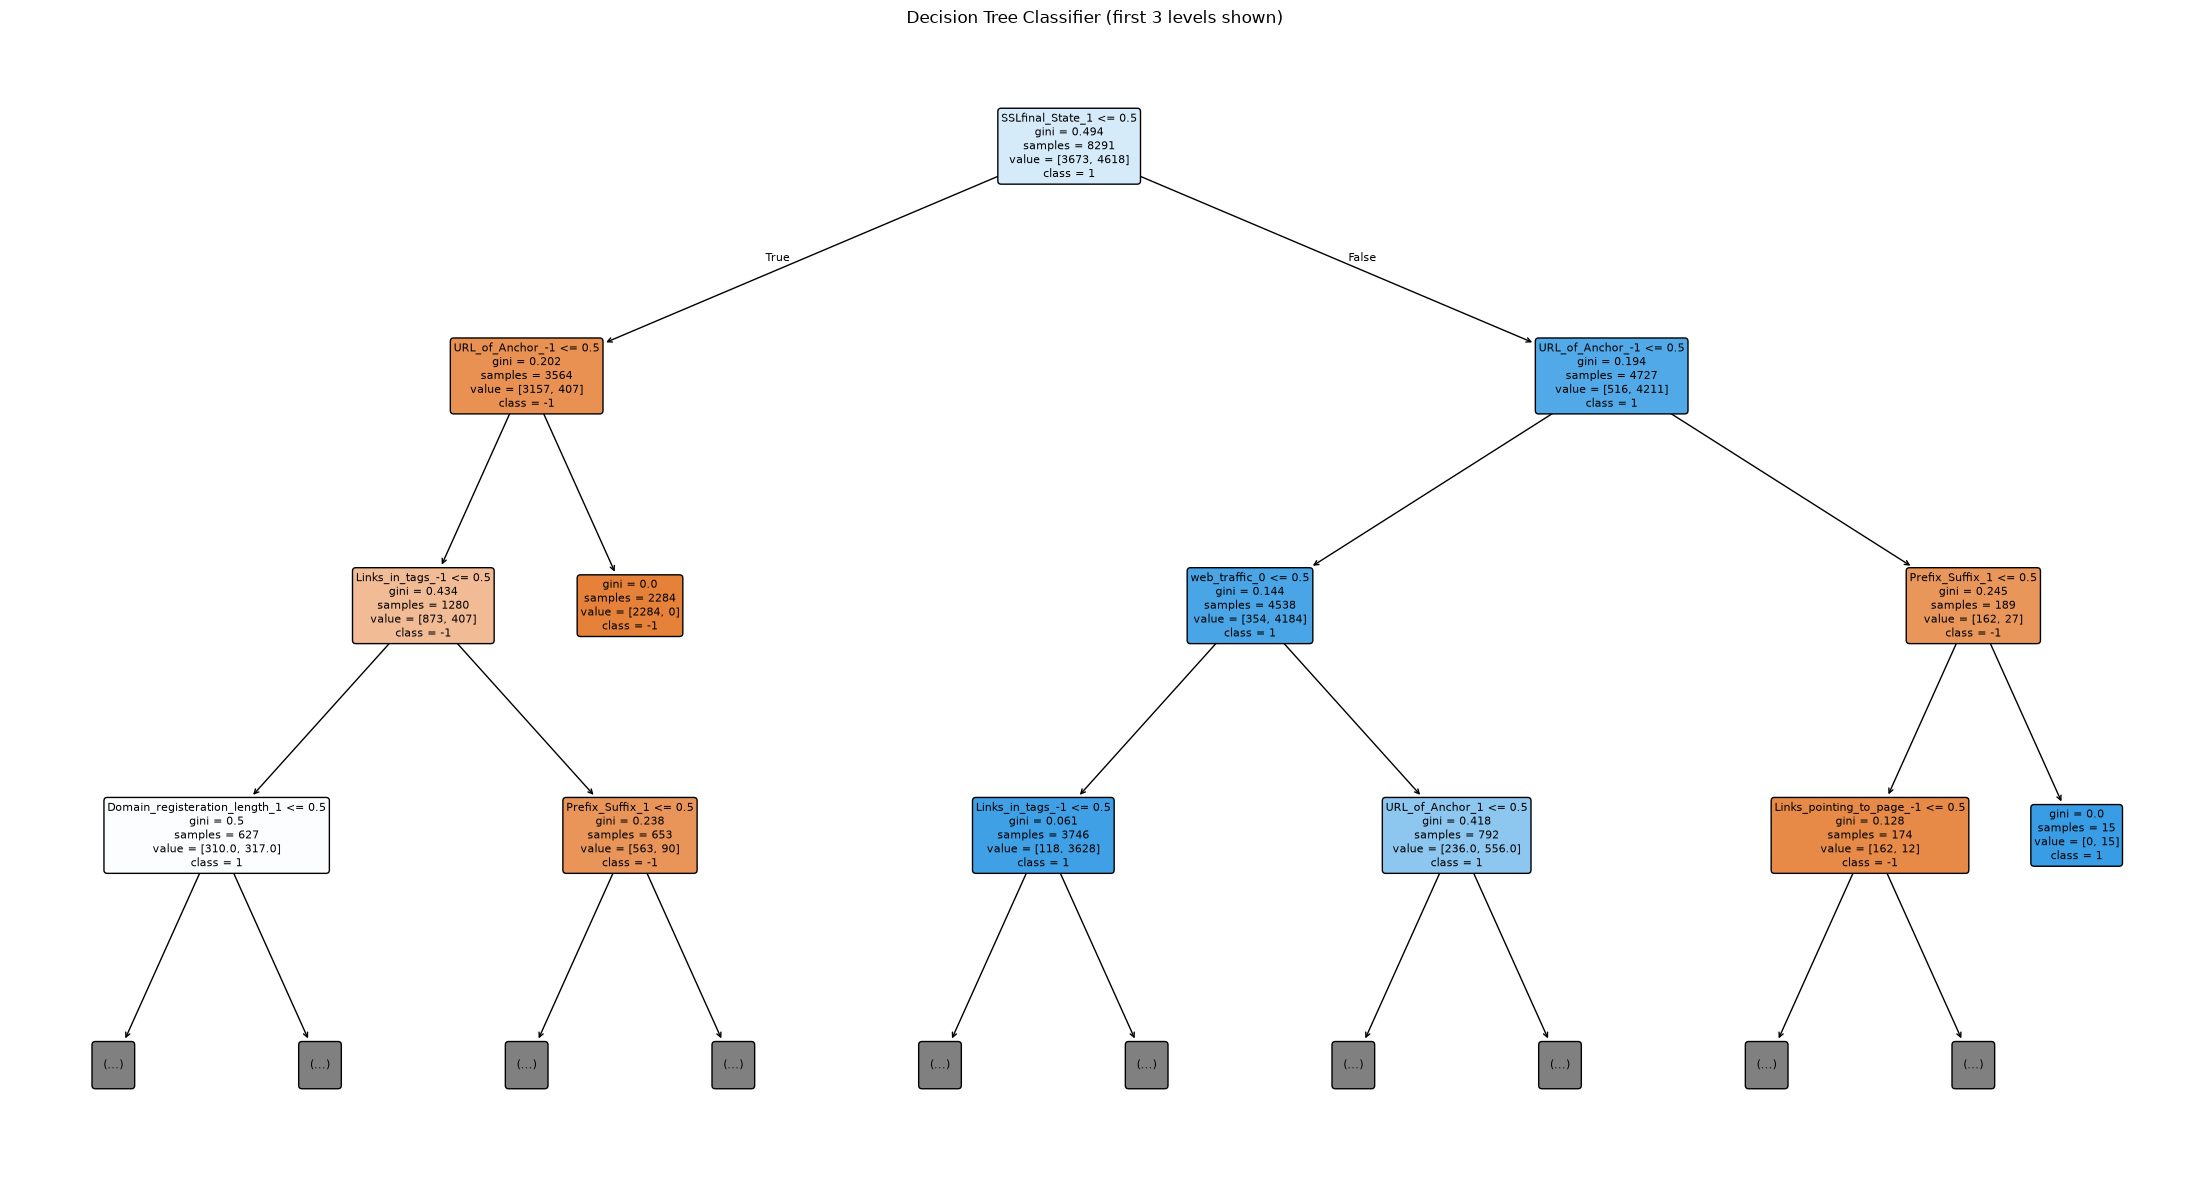

In [14]:
plt.figure(figsize=(22, 12))
plot_tree(
    dt_gini,
    feature_names=X_train.columns.tolist(),
    class_names=[str(label) for label in dt_gini.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree Classifier (first 3 levels shown)")
plt.tight_layout()
plt.show()

The visualization is limited to the first three levels for readability. The classifier itself is still the full trained tree; `max_depth=3` here only limits what is drawn.

### 11. Tune hyperparameters using GridSearchCV

In [15]:
param_grid = {
    "max_depth": [None, 3, 5, 10, 15, 20],
    "min_samples_split": [2, 5, 10, 20],
    "criterion": ["gini", "entropy"]
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_tree = grid_search.best_estimator_
y_pred_tuned = best_tree.predict(X_test)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation accuracy:", grid_search.best_score_)
print("Tuned model test accuracy:", accuracy_score(y_test, y_pred_tuned))

Best parameters: {'criterion': 'entropy', 'max_depth': 20, 'min_samples_split': 2}
Best cross-validation accuracy: 0.9585090208687346
Tuned model test accuracy: 0.9692474674384949


Cross-validation selects hyperparameters using only the training data. The held-out test set is used afterward for a less biased final evaluation.

### 12. Save, reload, and predict with the trained model

In [16]:
model_file = "phishing_decision_tree.joblib"

joblib.dump(best_tree, model_file)
print("Saved model to:", model_file)

Saved model to: phishing_decision_tree.joblib


In [17]:
loaded_model = joblib.load(model_file)

                                                                                    
new_samples = X_test.iloc[:5]
new_predictions = loaded_model.predict(new_samples)

print("Predictions from loaded model:", new_predictions)
display(new_samples)

Predictions from loaded model: ['-1' '1' '-1' '-1' '-1']


,having_IP_Address_-1,having_IP_Address_1,URL_Length_-1,URL_Length_0,URL_Length_1,Shortining_Service_-1,Shortining_Service_1,having_At_Symbol_-1,having_At_Symbol_1,double_slash_redirecting_-1,...,web_traffic_1,Page_Rank_-1,Page_Rank_1,Google_Index_-1,Google_Index_1,Links_pointing_to_page_-1,Links_pointing_to_page_0,Links_pointing_to_page_1,Statistical_report_-1,Statistical_report_1
6832,False,True,True,False,False,False,True,True,False,False,...,False,True,False,False,True,False,True,False,False,True
7288,False,True,False,False,True,False,True,False,True,False,...,True,True,False,False,True,False,True,False,False,True
2350,True,False,True,False,False,True,False,False,True,True,...,False,True,False,False,True,False,True,False,False,True
5909,True,False,True,False,False,False,True,False,True,False,...,False,False,True,False,True,False,False,True,True,False
7011,False,True,True,False,False,False,True,False,True,False,...,False,False,True,False,True,False,True,False,False,True


The example uses five held-out rows as new samples, so their feature columns match the training data exactly. For real new samples, provide the same feature columns in the same schema. Only load joblib files from trusted sources.

### Conclusion

Compare Gini, Entropy, and the tuned tree using test accuracy and the confusion matrix. The best hyperparameters are data-dependent and are printed by the notebook after it runs. Tree-based models generally do not require feature scaling, but the experiment records the results for this dataset.